# Member 4: Research Analysis and Data Storytelling
**Data Engineering and Visualization, Winter 2026**
**Author:** Member 4

## Datasets

| Role | Dataset | Catalog ID | Link |
|---|---|---|---|
| Housing (cleaned by Member 1) | DOB NOW: Build – Job Application Filings | H5 | https://data.cityofnewyork.us/resource/w9ak-ipjd |
| Transportation (cleaned by Member 2) | Serious Injury Response, Tracking & Analysis Program (SIRTA) | T4 | https://data.cityofnewyork.us/Transportation/Serious-Injury-Response-Tracking-Analysis-Program-/xeqp-qz8h |
| Geography | Community Districts (boundaries) | – | https://data.cityofnewyork.us/d/5crt-au7u |

**Dataset overview.** The raw housing download has 975,975 rows and 95 columns; after cleaning, 547,928 jobs remain (one row per job). The raw SIRTA download has 13,754 rows and 23 columns; after cleaning, 13,307 crashes remain from 2022-01 to 2026-06, each with at least one severe injury or death. Both were integrated by Member 3 into one table of 59 community districts × 54 months (3,186 rows).

## Purpose

This notebook asks two questions about the integrated community-district data, and gives each one a chart and an interpretation with its limitations. The results describe associations and do not show causation.

## 1. Setup

Imports, plotting style, and the location of Member 3's integrated table, `cd_month.csv`. The notebook searches `outputs/member3_integration/` first.

In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.2f}".format)

# Member 3's integrated district-by-month table lives in outputs/member3_integration/
SEARCH_DIRS = [Path("../outputs/member3_integration"), Path("outputs/member3_integration"), Path("../outputs")]
MIN_FILINGS_FOR_RATIO = 5   # districts with fewer filings give unstable ratios (used in RQ2)

def find_file(file_name):
    """Look for an input file in the project's output folders."""
    for folder in SEARCH_DIRS:
        if (folder / file_name).exists():
            return folder / file_name
    raise FileNotFoundError(f"{file_name} not found. Put Member 3's outputs in outputs/member3_integration/.")

df = pd.read_csv(find_file("cd_month.csv"), low_memory=False)
print("Loaded cd_month.csv:", df.shape)
df.head()

Loaded cd_month.csv: (3186, 15)


,community_district,cd_label,borough,year_month,year,month,new_filings,new_units,is_large_pipeline_month,crashes,severe_inj,fatalities,ksi,history_known,repeat_location
0,101,MN 01,MANHATTAN,2022-01,2022,1,0,0,False,1,1,0,1,1,0
1,101,MN 01,MANHATTAN,2022-02,2022,2,1,0,False,1,1,0,1,1,0
2,101,MN 01,MANHATTAN,2022-03,2022,3,0,0,False,0,0,0,0,0,0
3,101,MN 01,MANHATTAN,2022-04,2022,4,0,0,False,0,0,0,0,0,0
4,101,MN 01,MANHATTAN,2022-05,2022,5,0,0,False,1,1,0,1,1,0


## 2. Input check (EDA and validation)

Before analysis I check Member 3's table: how many rows and columns, how many districts and months, whether any values are missing, and how the main counts are distributed. The expected result is 59 districts and 54 months (2022-01 to 2026-06), which gives 59 × 54 = 3,186 rows.

Rows: 3186 | Columns: 15
Districts: 59 (expected 59)
Months: 2022-01 to 2026-06 | 54 months (expected 54 )
Complete district × month grid: True

Missing values per column:


,community_district,cd_label,borough,year_month,year,month,new_filings,new_units,is_large_pipeline_month,crashes,severe_inj,fatalities,ksi,history_known,repeat_location
missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


,count,mean,std,min,25%,50%,75%,max
new_filings,"3,186.00",2.45,6.89,0.00,0.00,1.00,3.00,319.00
new_units,"3,186.00",44.65,125.85,0.00,0.00,4.00,28.00,"2,375.00"
crashes,"3,186.00",3.43,2.43,0.00,2.00,3.00,5.00,15.00
severe_inj,"3,186.00",3.66,2.74,0.00,2.00,3.00,5.00,18.00
fatalities,"3,186.00",0.07,0.33,0.00,0.00,0.00,0.00,5.00
ksi,"3,186.00",3.73,2.77,0.00,2.00,3.00,5.00,18.00


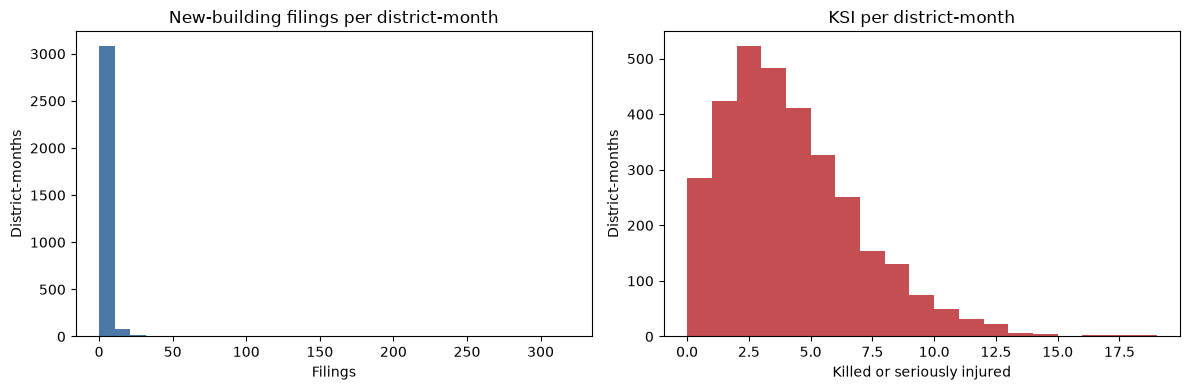

In [3]:
expected_months = len(pd.period_range("2022-01", "2026-06", freq="M"))   # 54

print("Rows:", len(df), "| Columns:", df.shape[1])
print("Districts:", df["community_district"].nunique(), "(expected 59)")
print("Months:", df["year_month"].min(), "to", df["year_month"].max(),
      "|", df["year_month"].nunique(), "months (expected", expected_months, ")")
print("Complete district × month grid:", len(df) == df["community_district"].nunique() * df["year_month"].nunique())

print("\nMissing values per column:")
display(df.isna().sum().to_frame("missing").T)

display(df[["new_filings", "new_units", "crashes", "severe_inj", "fatalities", "ksi"]].describe().T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["new_filings"], bins=30, color="#4C78A8")
axes[0].set_title("New-building filings per district-month")
axes[0].set_xlabel("Filings"); axes[0].set_ylabel("District-months")
axes[1].hist(df["ksi"], bins=range(0, int(df["ksi"].max()) + 2), color="#C44E52")
axes[1].set_title("KSI per district-month")
axes[1].set_xlabel("Killed or seriously injured"); axes[1].set_ylabel("District-months")
plt.tight_layout()
plt.show()

Most district-months have few or no filings and few or no serious crashes, so counts are small and skewed. That is why both questions below use totals or ratios over the whole period rather than single months.

## 3. Research question 1

**Which boroughs have the most killed or seriously injured (KSI) people per new housing unit, 2022–2026?**

*Why it matters:* a borough can have many crashes simply because it is large. Dividing harm by new housing capacity shows where serious harm is high relative to how much housing is being added. This helps planners see where street safety should be checked as development grows.

*Method:* for each borough, sum KSI and proposed new-building units over all months and districts, then compute KSI per 1,000 proposed units. The chart shows one bar per borough.

*Caution:* proposed units are plans, not residents, so this is not a per-person rate. KSI counts only crashes that could be placed in a district, so fatal crashes are under-represented (Member 2 and Member 3 document this).

,borough,new_units,ksi,districts,ksi_per_1000_units
4,STATEN ISLAND,4354,609,3,139.87
2,MANHATTAN,20353,2334,12,114.68
3,QUEENS,32727,3014,14,92.10
1,BROOKLYN,47014,3588,18,76.32
0,BRONX,37803,2344,12,62.01


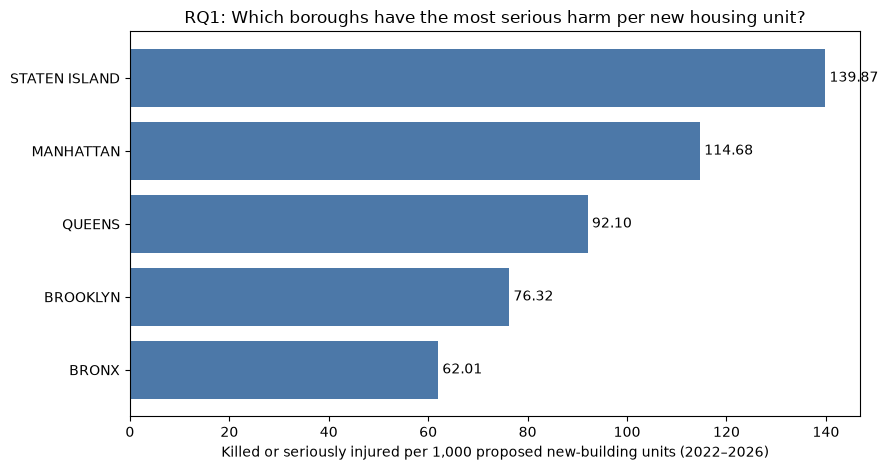

In [4]:
# Borough totals over 2022–2026: harm and new housing capacity
borough_totals = (df.groupby("borough", as_index=False)
                    .agg(new_units=("new_units", "sum"),
                         ksi=("ksi", "sum"),
                         districts=("community_district", "nunique")))
borough_totals["ksi_per_1000_units"] = 1000 * borough_totals["ksi"] / borough_totals["new_units"]
display(borough_totals.sort_values("ksi_per_1000_units", ascending=False))

ordered = borough_totals.sort_values("ksi_per_1000_units")
fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.barh(ordered["borough"], ordered["ksi_per_1000_units"], color="#4C78A8")
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_xlabel("Killed or seriously injured per 1,000 proposed new-building units (2022–2026)")
ax.set_title("RQ1: Which boroughs have the most serious harm per new housing unit?")
plt.tight_layout()
plt.show()

**Result.** [Staten Island has the highest rate, at 139.87 killed or seriously injured people per 1,000 proposed new-building units (2022–2026). The Bronx has the lowest, at 62.01, a gap of 77.86 per 1,000 units. Manhattan (114.68), Queens (92.10) and Brooklyn (76.32) fall in between.]

**Interpretation.** Higher ratios mean more serious harm for each new unit planned. The ratio is descriptive: it does not show whether new housing causes the harm, and boroughs differ in road type, traffic and density. A per-resident or per-road-mile comparison would test this more fairly.

## 4. Research question 2

**Do districts with bigger construction projects (more proposed units per filing) see more serious harm per filing?**

*Why it matters:* one large project and many small ones can add the same number of units, but they may bring different levels of traffic and risk. If bigger projects go with more harm per filing, large developments may need stronger traffic management.

*Method:* for each district, compute the average project size (units per new-building filing) and harm per filing (KSI per new-building filing). Districts with fewer than `MIN_FILINGS_FOR_RATIO` filings are excluded because their ratios are unstable. The chart shows one point per district, and the five districts with the highest harm per filing are labelled. The relationship is tested with Spearman rank correlation because the ratios are skewed.

*Caution:* a district with a few very large projects can have a high project size for reasons unrelated to safety. Harm per filing also depends on traffic and road design, which this data does not measure.

Spearman rho = 0.65 (p = 0.000) across 59 districts


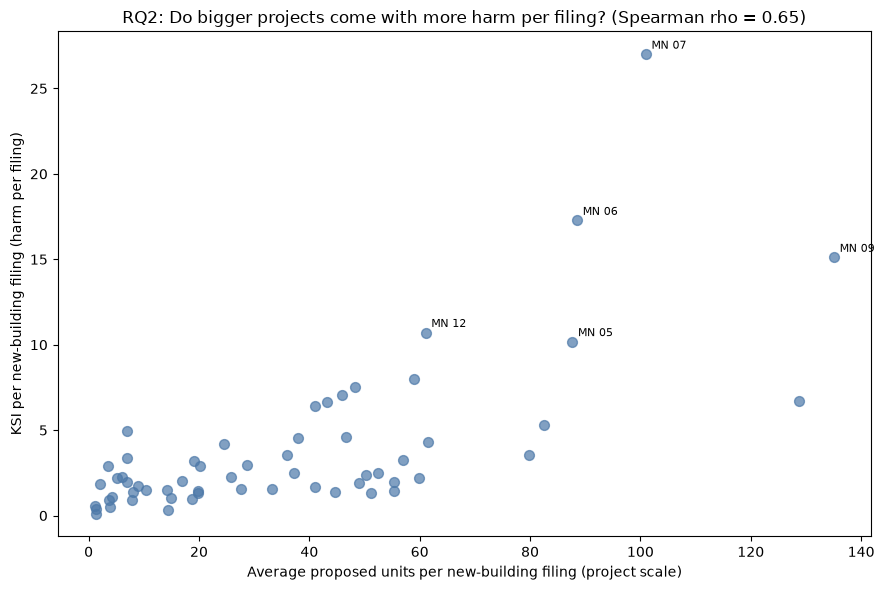

In [5]:
# District totals; keep districts with enough filings for a stable ratio
district = (df.groupby(["community_district", "cd_label", "borough"], as_index=False)
              .agg(new_filings=("new_filings", "sum"),
                   new_units=("new_units", "sum"),
                   ksi=("ksi", "sum")))
district = district[district["new_filings"] >= MIN_FILINGS_FOR_RATIO].copy()
district["units_per_filing"] = district["new_units"] / district["new_filings"]   # project scale
district["ksi_per_filing"] = district["ksi"] / district["new_filings"]           # harm per filing

rho, p_value = stats.spearmanr(district["units_per_filing"], district["ksi_per_filing"])
print(f"Spearman rho = {rho:.2f} (p = {p_value:.3f}) across {len(district)} districts")

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(district["units_per_filing"], district["ksi_per_filing"], s=50, alpha=0.7, color="#4C78A8")
for _, row in district.nlargest(5, "ksi_per_filing").iterrows():
    ax.annotate(row["cd_label"], (row["units_per_filing"], row["ksi_per_filing"]), fontsize=8,
                xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Average proposed units per new-building filing (project scale)")
ax.set_ylabel("KSI per new-building filing (harm per filing)")
ax.set_title(f"RQ2: Do bigger projects come with more harm per filing? (Spearman rho = {rho:.2f})")
plt.tight_layout()
plt.show()

**Result.** [Spearman rho = 0.65, p < 0.001, across 59 districts. Districts with larger average projects tend to have more serious harm per filing.]

**Interpretation.** [The correlation is positive and significant, so districts with larger average projects also tend to have more killed or seriously injured people per filing. This is an association. It may reflect traffic and road design rather than the projects themselves. A few districts sit well away from the rest (MN 07, MN 06, MN 09), so check the district table before relying on the pattern.]

## 5. Limitations

- **Association, not causation.** Districts with big projects may also have heavy traffic, so the results cannot show that projects cause harm.
- **Plans, not people.** Proposed units and filings are permit applications, not completed buildings or new residents, and there are no population or traffic denominators.
- **Incomplete crash placement.** Only crashes placed in a district are counted, and fatal crashes are under-represented, so harm is likely understated, especially in the fatal share.
- **Small counts and unstable ratios.** SIRTA only holds serious-injury crashes, and districts with few filings give unreliable ratios, so districts below the filing threshold are excluded from RQ2.
- **DOB NOW phase-in.** Filings from 2021 onward may partly reflect when filings moved into the system, not real construction activity.

## 6. Benefit to NYC

These results give planners and safety teams a simple starting list: boroughs where serious harm is high for each new unit, and districts where bigger projects coincide with more harm per filing. Those places can be checked first for traffic calming, work-zone management and crossing protection as development proceeds. The findings are a starting point for that review, not a verdict on any project.

## 7. Contributions (Member 4)

- Defined the research angle for my part and chose two questions that differ from the other members' questions (borough harm per housing unit; project size vs. harm per filing).
- Checked Member 3's integrated table: structure, grid completeness, missing values and distributions.
- Built and charted both research questions, with interpretations and limitations.
- Wrote the limitations and benefit to NYC for this notebook, and drafted the website story section (`website/story.md`).

## 8. Prompts used


1. [I got this error when I run the setup cell: [ModuleNotFoundError: No module named ‘scipy’] ]
2. [double check after me if my research questions overlap with my teammates’ questions in any way to avoid errors]